In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Normalization Layers

When we trained LeNet in that section, the learning rate that worked
smoothly for an MLP broke down: at 0.1, validation accuracy lingered at chance
for several epochs and reached only about 73% after ten, forcing us to boost
the learning rate twentyfold to 2.0 and train for 30 epochs to reach ~89%. We
encountered the same fragility in that section, where a peak learning
rate of 0.1 trained VGG cleanly yet caused NiN and GoogLeNet to stall or
diverge. A five-layer network ought not to be this sensitive to its step size.
Why does the usable learning rate depend so delicately on architecture, and
can we insert a layer inside the network to eliminate that fragility?

The root cause is how signal and gradient scales drift as they propagate
through depth. Each of LeNet's four sigmoid layers shrinks backpropagated
gradients by at least a factor of $1/4$, leaving early layers with tiny
updates compared with later ones so that no single learning rate fits the
whole network. Adding depth compounds the issue because every layer rescales
the activations entering the next. Although ReLU activations and careful
initialization (that section) balance activation variance at step
zero, nothing keeps those scales aligned once gradient updates begin moving
the weights.

*Batch normalization* [@Ioffe.Szegedy.2015] solves this dynamically
throughout training. Placed right before a layer's nonlinearity, it
standardizes each feature using the mean and variance of the current
minibatch, then applies a learned scale and shift. That simple transformation
stabilizes both forward activations and backward gradients while rendering
each normalized layer invariant to weight rescaling. As we will observe below,
adding batch normalization lets LeNet train cleanly not just at the MLP's
learning rate, but across a 300-fold range of step sizes. Alongside the
residual connections of the next section, batch normalization unlocked
networks over a hundred layers deep—even though researchers still debate the
exact mechanisms behind its full empirical power. Because batch normalization
couples examples within a minibatch, however, it degrades when minibatches are
very small; in the second half of this section we introduce *layer
normalization* and *group normalization*, which normalize each example on its
own.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Batch Normalization

### Standardizing over a Minibatch

Consider a single pre-activation feature computed by a fully connected layer
across a minibatch $\mathcal{B}$ of $m$ examples, producing scalar values
$x_1, \ldots, x_m$. Batch normalization computes their sample mean and sample
variance across the minibatch,

$$
\begin{aligned}
\hat{\mu}_{\mathcal{B}} &= \frac{1}{m} \sum_{i=1}^m x_i, \\
\hat{\sigma}^2_{\mathcal{B}} &= \frac{1}{m} \sum_{i=1}^m (x_i - \hat{\mu}_{\mathcal{B}})^2,
\end{aligned}
$$

and transforms each value via

$$
\textrm{BN}(x_i) = \gamma \, \frac{x_i - \hat{\mu}_{\mathcal{B}}}
{\sqrt{\hat{\sigma}^2_{\mathcal{B}} + \epsilon}} + \beta.
$$

The fraction standardizes the feature across the minibatch to zero mean and
variance $\hat{\sigma}^2_{\mathcal{B}} / (\hat{\sigma}^2_{\mathcal{B}} +
\epsilon)$, just shy of 1. The tiny constant $\epsilon > 0$ (typically
$10^{-5}$) guards against division by zero whenever all entries in the
minibatch coincide. In a layer with multiple features, each feature is
normalized independently using its own minibatch mean and variance.

As a concrete check, the four values $(2, 4, 6, 8)$ have mean 5 and variance
$(9 + 1 + 1 + 9)/4 = 5$, standardizing (up to $\epsilon$) to
$(x_i - 5)/\sqrt{5} \approx (-1.34, -0.45, 0.45, 1.34)$. Notice that
$(20, 40, 60, 80)$ and $(102, 104, 106, 108)$ map to the exact same four
numbers: standardization strips away both the arbitrary scale and the offset
of the incoming feature.

Zero mean and unit variance, however, are not necessarily ideal for every
downstream activation function—a sigmoid, for example, behaves nearly linearly
over unit-variance inputs. To restore full representational freedom,
the equation introduces a learnable *scale* $\gamma$ and *shift*
$\beta$ for each feature, initialized to $\gamma = 1$ and $\beta = 0$ and
trained alongside the network weights. Because setting $\gamma$ and $\beta$
to the dataset's true standard deviation and mean recovers the original
unnormalized feature (up to minibatch sampling fluctuations), batch
normalization does not reduce the expressive power of the network.

### Scale Invariance

Stripping away feature scale produces two powerful effects on optimization.
The first is immediate and directly explains how batch normalization rescues
LeNet: whenever a feature varies very little across a minibatch (for instance,
after passing through saturating sigmoids clustered near $1/2$), dividing by
its tiny standard deviation $\hat{\sigma}_{\mathcal{B}}$ restores unit variance
on the forward pass, and by the chain rule amplifies its backpropagated
gradient by the same factor $1/\hat{\sigma}_{\mathcal{B}}$. Vanishing signals
and vanishing gradients are both automatically rescaled.

The second effect is subtler and acts on the layer weights themselves. Write
$x_i = \mathbf{w}^\top \mathbf{h}_i + b$ for the pre-activation of example
$i$. Scaling $\mathbf{w}$ and $b$ by any positive constant $a > 0$ scales
every $x_i$, their mean, and their standard deviation by $a$, leaving the
normalized output unchanged (ignoring $\epsilon$):

$$\textrm{BN}(a \mathbf{w}^\top \mathbf{h}_i + a b) =
\textrm{BN}(\mathbf{w}^\top \mathbf{h}_i + b).$$

Consequently, the loss depends only on the *direction* of $\mathbf{w}$, not
its Euclidean norm. Differentiating both sides with respect to $\mathbf{w}$
reveals that the gradient at $a \mathbf{w}$ equals $1/a$ times the gradient
at $\mathbf{w}$ [@Ioffe.Szegedy.2015]: small weights receive larger
gradients while large weights receive smaller ones.

Consider what happens if we choose an overly aggressive learning rate $\eta$.
Because the loss is constant along the radial ray of $\mathbf{w}$, the
gradient $\mathbf{g}$ is orthogonal to $\mathbf{w}$, so every SGD step
strictly increases the weight norm:
$\|\mathbf{w} - \eta \mathbf{g}\|^2 = \|\mathbf{w}\|^2 + \eta^2 \|\mathbf{g}\|^2$.
An excessively large step inflates $\|\mathbf{w}\|$ rapidly, which in turn
shrinks all subsequent gradients by the same factor—creating a built-in
self-stabilizing feedback loop for large learning rates
[@Arora.Li.Lyu.2019].

Keep the caveats of this analysis in mind. Strictly speaking, it assumes
plain SGD without weight decay (under weight decay, weight norms reach an
equilibrium where outward gradient growth balances inward decay); it applies
only to layers immediately followed by normalization (not the final output
layer of a classifier); and it cannot stop divergence during the very first
few steps before weight norms grow. Even with those caveats, scale invariance
provides our clearest explanation for why normalized networks tolerate vastly
wider learning-rate ranges.

### Fully Connected and Convolutional Layers

For a fully connected layer with weights $\mathbf{W}$, bias $\mathbf{b}$, and
nonlinearity $\phi$, batch normalization is placed between the affine
transformation and the activation function, as proposed in
@Ioffe.Szegedy.2015:

$$\mathbf{h} = \phi(\textrm{BN}(\mathbf{W}\mathbf{x} + \mathbf{b})).$$

Here each output unit is treated as a separate feature with its own minibatch
mean, variance, $\gamma_j$, and $\beta_j$.

For a convolutional layer, batch normalization respects translation
equivariance by treating each output *channel* as one feature, computing a
single mean and variance across both the $m$ minibatch examples *and* all
$p \times q$ spatial locations ($m \cdot p \cdot q$ values per channel). In
LeNet's first convolutional layer (6 channels of $28 \times 28$ with batch
size 128), each channel's statistics pool $128 \cdot 28 \cdot 28 = 100{,}352$
entries—far more stable than the 128 entries per unit in a dense layer. Each
channel likewise shares a single scalar $\gamma$ and $\beta$ across all
spatial coordinates so that the normalized layer remains shift-equivariant.

### Training and Prediction

At inference time, a deployed model often scores one image at a time, and its
prediction for a given input must be deterministic rather than dependent on
whatever other images happen to share its minibatch. Batch normalization
therefore operates in two distinct modes. In *training mode*, it normalizes
using the current minibatch's statistics as in the equation, while
updating exponential moving averages $\hat{\mu}$ and $\hat{\sigma}^2$
(initialized to 0 and 1) after every step:

$$
\begin{aligned}
\hat{\mu} &\leftarrow \rho \, \hat{\mu} + (1 - \rho) \, \hat{\mu}_{\mathcal{B}}, \\
\hat{\sigma}^2 &\leftarrow \rho \, \hat{\sigma}^2 + (1 - \rho) \, \hat{\sigma}^2_{\mathcal{B}}.
\end{aligned}
$$

The *decay* $\rho$ governs the effective window of these running statistics: a
minibatch from $k$ steps ago carries weight $(1 - \rho)\rho^k$. At
$\rho = 0.9$, weights halve roughly every seven steps, averaging over roughly
the most recent $1/(1 - \rho) = 10$ minibatches (out of 469 minibatches of
size 128 per Fashion-MNIST epoch). In *prediction mode*, the layer freezes
these running estimates and normalizes every input with them, reducing batch
normalization to a fixed, deterministic affine transformation. Like dropout
(that section), batch normalization thus behaves differently during
training and evaluation.

Watch out for a notorious API inconsistency across libraries: some frameworks
name the parameter $\rho$ `momentum`, whereas others name $1 - \rho$
`momentum`—and neither has anything to do with optimization momentum.
Throughout this chapter we standardize on $\rho = 0.9$ and $\epsilon = 10^{-5}$,
passing them explicitly wherever a framework's defaults differ.

## Implementation from Scratch

Below, `batch_norm` implements both the equation and
the equation across training and prediction modes for both fully
connected (2D) and convolutional (4D) inputs.
<!-- d2l:prose id=batch-norm-md-3 fw=tensorflow, jax -->

Images are stored as (examples, height, width, channels), so the channel
axis is the last.

In [2]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum,
               training):
    if not training:
        # Prediction mode: normalize with the running estimates
        X_hat = (X - moving_mean[...]) / jnp.sqrt(moving_var[...] + eps)
    else:
        assert X.ndim in (2, 4)
        # Channels last: average over every axis except the last one
        axes = tuple(range(X.ndim - 1))
        mean = X.mean(axis=axes, keepdims=True)
        var = ((X - mean) ** 2).mean(axis=axes, keepdims=True)
        X_hat = (X - mean) / jnp.sqrt(var + eps)
        # Update the running estimates in place; `momentum` is the decay rho
        moving_mean[...] = momentum * moving_mean[...] + (1.0 - momentum) * mean
        moving_var[...] = momentum * moving_var[...] + (1.0 - momentum) * var
    return gamma * X_hat + beta  # Scale and shift

Wrapping `batch_norm` in a `BatchNorm` layer requires tracking two distinct
kinds of state: learnable parameters (`gamma` and `beta`) updated by the
optimizer, and non-trainable buffers (`moving_mean` and `moving_var`) that
the optimizer ignores yet the module still saves to disk and transfers to GPUs
alongside its weights.

In [3]:
class BatchNorm(nnx.Module):
    # `num_features`: outputs of a fully connected layer or channels of a
    # convolutional layer. `num_dims`: 2 or 4, the number of input axes
    def __init__(self, num_features, num_dims, deterministic=False):
        self.deterministic = deterministic  # True in prediction mode
        shape = (1, num_features) if num_dims == 2 else (1, 1, 1, num_features)
        # Scale and shift, learned, start at 1 and 0
        self.gamma = nnx.Param(jnp.ones(shape))
        self.beta = nnx.Param(jnp.zeros(shape))
        # Running estimates, not learned, start at 0 and 1
        self.moving_mean = nnx.BatchStat(jnp.zeros(shape))
        self.moving_var = nnx.BatchStat(jnp.ones(shape))

    def set_view(self, *, deterministic):
        self.deterministic = deterministic

    def __call__(self, X):
        return batch_norm(X, self.gamma, self.beta, self.moving_mean,
                          self.moving_var, eps=1e-5, momentum=0.9,
                          training=not self.deterministic)

NNX keeps the running estimates in `BatchStat` variables, which the
optimizer ignores since it updates only `Param`s. The Trainer creates a
training view of the model with `deterministic=False` and a prediction view
with `deterministic=True`; `set_view` receives this flag.

To verify our from-scratch implementation, we run both `BatchNorm` and the
framework's built-in layer (each with $\rho = 0.9$ and $\epsilon = 10^{-5}$)
on an identical minibatch of 128 six-channel $28 \times 28$ feature maps
drawn with mean 2 and standard deviation 3. Below we check that every output
channel has mean 0 and variance 1, that our output matches the framework's
built-in layer, and that the running means update properly after one step.

In [4]:
X = 2 + 3 * jax.random.normal(d2l.get_key(), (128, 28, 28, 6))
bn = BatchNorm(6, num_dims=4)  # Training mode
bn_ref = nnx.BatchNorm(6, momentum=0.9, epsilon=1e-5, use_fast_variance=False,
                       use_running_average=False,
                       rngs=nnx.Rngs(d2l.get_key()))
Y, Y_ref = bn(X), bn_ref(X)
{'largest channel mean': float(jnp.abs(Y.mean(axis=(0, 1, 2))).max()),
 'average channel variance': float(Y.var(axis=(0, 1, 2)).mean()),
 'largest difference': float(jnp.abs(Y - Y_ref).max()),
 'running means': bn.moving_mean[...].reshape(-1)}

{'largest channel mean': 9.396854494525542e-08,
 'average channel variance': 0.9999990463256836,
 'largest difference': 4.76837158203125e-07,
 'running means': Array([0.20013797, 0.20052281, 0.1993001 , 0.20045717, 0.1992819 ,
        0.19969386], dtype=float32)}

Every channel now has zero mean and unit variance up to single-precision
roundoff, and our implementation matches the built-in layer to within
$10^{-6}$. After a single minibatch, the running means have moved a fraction
$1 - \rho = 0.1$ of the way from 0 toward the minibatch mean of 2.


## LeNet with Batch Normalization

Let us now return to LeNet (that section) and put batch normalization
to the test. Keeping the exact same Xavier initialization, `BNLeNet` inserts
a built-in batch normalization layer after each of LeNet's four hidden layers
(the 6- and 16-channel convolutions and the 120- and 84-unit dense layers)
right before each sigmoid activation. Notice that we disable biases on those
four layers: subtracting the minibatch mean completely cancels any additive
bias immediately preceding batch normalization, while $\beta$ takes over its
role. Across all $6 + 16 + 120 + 84 = 226$ normalized features, trading 226
biases for 226 $(\gamma, \beta)$ pairs adds just 226 trainable parameters to
LeNet's 61,706.

In [5]:
class BNLeNet(d2l.Classifier):
    """LeNet with batch normalization before each hidden sigmoid."""
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10, rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rngs'])
        rngs = nnx.Rngs(d2l.get_key()) if rngs is None else rngs
        init = dict(kernel_init=nnx.initializers.xavier_uniform(), rngs=rngs)
        bn = lambda n: nnx.BatchNorm(n, momentum=0.9,  # rho = 0.9
                                     use_fast_variance=False, rngs=rngs)
        nb = dict(use_bias=False, **init)  # No biases before BN

        def avg_pool(x):  # 2x2 windows, stride 2
            return nnx.avg_pool(x, window_shape=(2, 2), strides=(2, 2))

        def flatten(x):  # One vector per example
            return x.reshape((x.shape[0], -1))

        self.net = nnx.Sequential(
            nnx.Conv(1, 6, kernel_size=(5, 5), padding=2, **nb), bn(6),
            nnx.sigmoid, avg_pool,
            nnx.Conv(6, 16, kernel_size=(5, 5), padding='VALID', **nb),
            bn(16), nnx.sigmoid, avg_pool, flatten,
            nnx.Linear(400, 120, **nb), bn(120), nnx.sigmoid,
            nnx.Linear(120, 84, **nb), bn(84), nnx.sigmoid,
            nnx.Linear(84, num_classes, **init))

Flax's `nnx.BatchNorm` defaults to `momentum=0.99`, so we pass
$\rho = 0.9$; its `epsilon` defaults to $10^{-5}$. By default it also
computes the variance as the mean of the squares minus the square of the
mean, which loses precision when the mean is large compared with the standard
deviation; `use_fast_variance=False` subtracts the mean before squaring, as
our implementation does. Flax pads to `'SAME'` by default, so the second
convolution asks for `'VALID'`, and the flattened output has
$16 \cdot 5 \cdot 5 = 400$ entries.

Before training, notice a subtle interaction between prediction mode and the
learning rate. Because the running averages lag behind by roughly ten
minibatches, whenever the network weights are still changing rapidly those
averages describe a slightly stale snapshot of the network. This is not merely
theoretical: under a constant learning rate of 0.1, `BNLeNet`'s
prediction-mode validation accuracy can suddenly dip by 10 percentage points
or more on individual epochs, including the final one. Decaying the learning
rate smoothly to zero fixes this cleanly: as the step size shrinks, the
weights settle and the running averages lock onto the final network. We
therefore reuse the warmup-and-cosine schedule from
that section (studied further in that section), warming
up over the first tenth of `num_steps`, and wrap `d2l.LeNet` in a subclass
`CosineLeNet` so both models share the exact same schedule.

In [6]:
@d2l.add_to_class(BNLeNet)
def configure_optimizers(self):
    return optax.sgd(lambda t: self.lr * d2l.cosine_warmup(
        t, self.num_steps, self.num_steps // 10))

class CosineLeNet(d2l.LeNet):
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10, rngs=None):
        super().__init__(lr, num_classes, rngs=rngs)
        self.num_steps = num_steps

    configure_optimizers = BNLeNet.configure_optimizers

Let us train both `CosineLeNet` and `BNLeNet` under identical settings (peak
learning rate 0.1, batch size 128, and 10 epochs) and track
validation accuracy epoch by epoch.

In [7]:
data = d2l.FashionMNIST(batch_size=128)
num_steps = 10 * len(data.train_dataloader())
curves = {}
for model in (CosineLeNet(0.1, num_steps), BNLeNet(0.1, num_steps)):
    trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
    trainer.board.display = False  # We plot the accuracies ourselves
    trainer.fit(model, data)
    curves[type(model).__name__] = trainer.history['val_acc']

Plotting the epoch-by-epoch validation accuracy trajectories stored in `curves`
contrasts the convergence speed of `CosineLeNet` and `BNLeNet` directly.

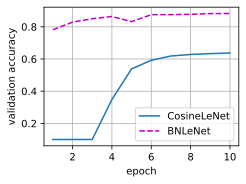

In [8]:
d2l.plot(list(range(1, 11)), list(curves.values()), 'epoch',
         'validation accuracy', legend=list(curves))

We also print the final 10-epoch validation accuracy `acc[-1]` from `curves`
for both models to compare their endpoint performance.

In [9]:
{name: round(acc[-1], 3) for name, acc in curves.items()}  # After 10 epochs

{'CosineLeNet': 0.637, 'BNLeNet': 0.883}

Without batch normalization, LeNet stalls at chance (10%) for the first two to
five epochs and reaches only around 60% after ten (lower than the 73% in
that section, plausibly because the cosine decay halves the average
step size). With batch normalization, the exact same architecture clears 70%
in its very first epoch and climbs to ~88% after ten—nearly matching the
88--90% that unnormalized LeNet required twenty times the learning rate and
three times as many epochs to attain. Notice also how smoothly the curve
flattens over the final epochs as the learning rate anneals to zero. Adding
just 226 parameters did not expand the network's representational capacity; it
simply brought every layer's activations and gradients onto a healthy scale.

Comparing at a single learning rate, however, leaves open an important
question: did batch normalization merely shift the sweet spot to a different
step size, or does it truly widen the range of workable learning rates? To
find out, we sweep peak learning rates across a 300-fold span from 0.03 to 10
and plot final 10-epoch validation accuracy for both models.

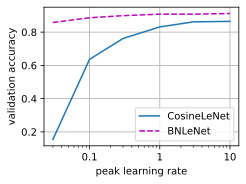

In [10]:
lrs = (0.03, 0.1, 0.3, 1, 3, 10)
final = {'CosineLeNet': [], 'BNLeNet': []}
for lr in lrs:
    for cls in (CosineLeNet, BNLeNet):
        trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
        trainer.board.display = False
        trainer.fit(cls(lr, num_steps), data)
        final[cls.__name__].append(trainer.history['val_acc'][-1])
d2l.plot(list(lrs), list(final.values()), 'peak learning rate',
         'validation accuracy', legend=list(final), xscale='log')

The sweep gives a decisive answer. Plain LeNet succeeds only in a narrow band
around 1 to 3 (reaching 84--87%): below that window it learns too slowly in
10 epochs, and at 10 it becomes erratic, sometimes stalling at chance. By
contrast, `BNLeNet` clears ~85% at *every* learning rate from 0.03 to 10, and
reaches ~91% at rates of 1 and above (three full points higher than at 0.1).
Where the unnormalized network must be tuned within a factor of three, the
normalized network works smoothly across a factor of 300—just as our
scale-invariance analysis predicted (though the ceiling cannot extend forever,
since the final output layer remains unnormalized).

Why batch normalization helps deep networks so dramatically goes beyond internal covariate shift [@Ioffe.Szegedy.2015]: subsequent studies showed that it smooths the loss landscape and gradients [@Santurkar.Tsipras.Ilyas.ea.2018], keeps activation and gradient scales balanced across depth, renders hidden weights scale-invariant so large learning rates self-stabilize, and injects mild minibatch noise that regularizes like dropout [@Luo.Wang.Shao.ea.2018; @brock2021nfnet].

## Normalization without Batch Statistics

Coupling an example's output to the other examples in its minibatch is an
unusual property for a neural network layer, and it introduces two practical
weaknesses. First, minibatch statistics deteriorate as batch size shrinks. In
the extreme case of a fully connected layer with a minibatch of one example,
every entry equals its own mean, forcing every standardized activation to 0 so
the layer outputs a constant $\beta$ regardless of the input. Memory-heavy
tasks such as object detection and semantic segmentation often fit only one or
two high-resolution images per GPU, precisely where batch statistics are
noisiest. Second, batch normalization computes two different functions in
training and prediction modes; whenever running estimates drift out of sync
with test-time inputs (for instance, after fine-tuning across domains),
accuracy can degrade silently in ways that are notoriously hard to debug.

Both limitations vanish if we compute normalization statistics *within each
example independently*. the figure compares the resulting family
of normalization layers on a convolutional activation tensor with batch axis
$N$, channel axis $C$, and spatial axes $H \cdot W$: every variant uses the
exact same standardization formula and differs solely in which entries are
grouped together to share a mean and variance.

![Normalization methods for activations with examples $N$, channels $C$, and spatial positions $H\cdot W$. The shaded numbers share one mean and one variance. Batch normalization averages each channel over the minibatch and all positions; layer normalization averages each example over all channels and positions; group normalization over a group of channels and all positions; instance normalization over a single channel. The layer normalization of transformers and ConvNeXt averages over the channels at one position.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-norm-axes.svg)

### Layer Normalization

*Layer normalization* [@Ba.Kiros.Hinton.2016] standardizes all $n$
features $\mathbf{x} = (x_1, \ldots, x_n)$ of a single example independently:

$$
\begin{aligned}
\textrm{LN}(\mathbf{x})_j &= \gamma_j \, \frac{x_j - \hat{\mu}}{\sqrt{\hat{\sigma}^2 + \epsilon}} + \beta_j, \\
\textrm{with} \quad \hat{\mu} &= \frac{1}{n} \sum_{j=1}^n x_j \quad \textrm{and} \quad \hat{\sigma}^2 = \frac{1}{n} \sum_{j=1}^n (x_j - \hat{\mu})^2.
\end{aligned}
$$

This is the equation transposed: instead of averaging one feature
across examples, we average one example across its features while keeping the
learnable scale $\gamma_j$ and shift $\beta_j$ per feature. Because no other
example enters the computation, layer normalization behaves identically at
every batch size and in both training and prediction modes, requiring no
running statistics at all. Note that in practice the exact axes pooled by
"layer normalization" depend on the architecture: in convolutional tensors it
may pool across all channels and spatial positions of an example (second panel
of the figure), whereas Transformers normalize each token's
feature vector independently and ConvNeXt (that section) similarly
normalizes the channel vector at each individual pixel without pooling across
space (rightmost panel).

### Group and Instance Normalization

Tailored specifically to convolutional layers, *group normalization*
[@wu2018groupnorm] partitions the $c$ channels into $G$ groups of $c/G$
channels and standardizes each example over each group's
$(c/G) \cdot p \cdot q$ entries, followed by a per-channel learned scale and
shift. It smoothly interpolates between two extremes: $G = 1$ pools across
every channel and position (spatial layer normalization in
the figure), whereas $G = c$ normalizes each channel of each
example on its own, known as *instance normalization*. Intermediate choices
(typically $G = 32$) provide enough elements per group for reliable statistics
without forcing unrelated feature channels to share a single mean and
variance. Below we verify on a batch of 32 tensors (16 channels, 4 groups)
that every `(example, group)` slice is standardized to zero mean and unit
variance and that normalizing the first example alone produces the exact same
output as normalizing it inside the full batch.

In [11]:
X = jax.random.normal(d2l.get_key(), (32, 8, 8, 16))  # Channels last
gn = nnx.GroupNorm(16, num_groups=4, epsilon=1e-5,
                   rngs=nnx.Rngs(d2l.get_key()))
Y = gn(X)
# Collect each (example, group) pair's numbers
G = jnp.transpose(Y, (0, 3, 1, 2)).reshape(32, 4, -1)
(jnp.abs(G.mean(axis=2)).max(), G.var(axis=2).mean(),
 jnp.abs(gn(X[:1]) - Y[:1]).max())

(Array(2.6077032e-08, dtype=float32),
 Array(0.9999897, dtype=float32),
 Array(4.7683716e-07, dtype=float32))

As expected, every group achieves zero mean and unit variance up to roundoff,
and the first example's output is strictly independent of the rest of the
batch. Does this independence carry an accuracy tradeoff? At large batch sizes,
only a tiny one: on ImageNet with ResNet-50 and 32 images per GPU,
@wu2018groupnorm report 23.6% top-1 error for batch normalization
versus 24.1% for group normalization. Drop to 2 images per GPU, however, and
batch normalization's error spikes to 34.7% while group normalization holds
steady at 24.1%—making group normalization the standard choice for detection
and segmentation models trained with small per-GPU batches.

### Normalizer-Free Networks

Activation normalization is not the only way to keep signal scales well
behaved in deep convnets. *Normalizer-free networks* (NFNets)
[@brock2021nfnet] trained deep ResNet-style architectures without a single
normalization layer to state-of-the-art ImageNet accuracy (among models
trained solely on ImageNet). Rather than normalizing activations, NFNets
standardize each convolutional kernel's weights directly, preserving throughout
training the variance balance that initialization (that section)
establishes only at step zero, and pair this with adaptive gradient clipping
relative to each weight tensor's norm. Although we will not implement NFNets
here, their success offers illuminating evidence: the fact that deep convnets
train just as well when signal scale is controlled through weights instead of
activations strongly supports the view that scale control is the core job of a
normalization layer.

## Summary

Batch normalization standardizes each feature of a dense layer, or each channel
of a convolutional layer, using the mean and variance of the current minibatch,
followed by a learned scale and shift. By keeping forward signals and backward
gradients properly scaled and making normalized layers invariant to weight
norms, it lets LeNet train smoothly across peak learning rates spanning 0.03
to 10 (a 300-fold band compared with a 3-fold band without it), even though
the full theoretical explanation for its deep-network benefits remains open.
At inference time, batch normalization switches to frozen exponential moving
averages of the training statistics. Because coupling across examples breaks
down at tiny batch sizes, layer normalization and group normalization compute
their statistics strictly within each example, eliminating both batch-size
sensitivity and the train--test mode split. In the next section, we combine
batch normalization with residual connections to push network depth past a
hundred layers.

## Exercises

1. **Bias before batch norm.** `BNLeNet` builds its four normalized layers without a bias. Show from the equation that adding a bias $\mathbf{b}$ before batch normalization changes neither the training-mode output nor the weight gradients, and that $\partial L / \partial \mathbf{b} = \mathbf{0}$. What happens to such a bias in prediction mode?

1. [code] **Learning-rate ceiling.** In the sweep of this section, `BNLeNet` trained cleanly at every peak rate up to 10.
    1. Extend the sweep for `BNLeNet` to peak rates of 30, 100, and 300. Where does training break down?
    1. The output linear layer is the only weight layer not followed by batch normalization. Test whether it sets the ceiling by fixing the output layer's learning rate at 0.1 while sweeping the normalized layers' peak rate across 30, 100, and 300.
    1. Replace the sigmoids in both `CosineLeNet` and `BNLeNet` with ReLUs (using He initialization) and repeat the learning-rate sweep. How does the workable band of the unnormalized network change, and why?

1. [code] **Running averages and recomputed statistics.** The decay $\rho$ in the equation determines how many recent minibatches the running statistics average over.
    1. After how many steps does a minibatch's weight in the running mean fall below 1% of the newest minibatch's weight for $\rho = 0.9$ and $\rho = 0.99$? Compare both horizons against the 469 steps of one Fashion-MNIST epoch.
    1. Train `BNLeNet` for 10 epochs at a constant learning rate of 0.1 (`d2l.Classifier.configure_optimizers`). After every epoch, evaluate the model twice: once in prediction mode using its running averages, and once after recomputing fresh statistics over 100 training minibatches with weights frozen. Plot both validation curves alongside the cosine-schedule curve and explain the gap.

1. [code] **Minibatch coupling.** Because batch normalization couples examples within a minibatch, evaluate a trained `BNLeNet` on the validation set in three ways (measuring prediction mode first so training-mode passes do not overwrite the running statistics): (i) prediction mode, (ii) training mode with validation batch size 128, and (iii) training mode with validation batch size 2 (or 1). Explain the three resulting accuracies.

1. [code] **Small-batch training: BatchNorm vs. GroupNorm/LayerNorm.** ● Build a variant of `BNLeNet` that replaces `BatchNorm` with group normalization (2 groups) after the two convolutional layers and layer normalization (that section) after the two hidden dense layers. Train both `BNLeNet` and this variant for 2 epochs at batch size 4 and at batch size 128. How does each model's validation accuracy change when the batch size drops from 128 to 4, and why?

1. [code] **Backward pass of batch norm.** ● Because $\hat{\mu}_{\mathcal{B}}$ and $\hat{\sigma}^2_{\mathcal{B}}$ in the equation depend on every element of the minibatch, the backward pass of batch normalization couples all $m$ examples.
    1. Derive by hand the gradient $\partial L / \partial x_i$ of a scalar loss $L$ with respect to each input $x_i$ of a 1D batch-norm layer, and show from your formula that $\sum_{i=1}^m \partial L / \partial x_i = 0$ identically.
    1. Implement your backward formula and verify that it matches automatic differentiation to machine precision.

[Discussions](https://d2l.discourse.group/t/18005)